**Downloading the data**

In [1]:
!wget -q -O /content/brca_metabric.tar.gz "https://datahub.assets.cbioportal.org/brca_metabric.tar.gz"
!ls -lh /content/brca_metabric.tar.gz
!head -c 2 /content/brca_metabric.tar.gz | xxd
!tar -tzf /content/brca_metabric.tar.gz | grep -i clinical

-rw-r--r-- 1 root root 487M Nov 19  2025 /content/brca_metabric.tar.gz
/bin/bash: line 1: xxd: command not found
brca_metabric/data_clinical_patient.txt
brca_metabric/data_clinical_sample.txt
brca_metabric/meta_clinical_sample.txt
brca_metabric/meta_clinical_patient.txt


**Extracting the clinical data**

In [2]:
!mkdir -p /content/data
!tar -xzf /content/brca_metabric.tar.gz -C /content/data --wildcards '*clinical*'
!ls /content/data/brca_metabric

data_clinical_patient.txt  meta_clinical_patient.txt
data_clinical_sample.txt   meta_clinical_sample.txt


**Load the data**

In [3]:
import pandas as pd

study = "/content/data/brca_metabric"
patients = pd.read_csv(f"{study}/data_clinical_patient.txt", sep="\t", comment="#")
samples  = pd.read_csv(f"{study}/data_clinical_sample.txt",  sep="\t", comment="#")
clinical = patients.merge(samples, on="PATIENT_ID")
clinical.shape

(2509, 36)

**Creating a wide table**

Clinical base (one row per patient)

In [4]:
import pandas as pd
study = "/content/data/brca_metabric"

patients = pd.read_csv(f"{study}/data_clinical_patient.txt", sep="\t", comment="#")
samples  = pd.read_csv(f"{study}/data_clinical_sample.txt",  sep="\t", comment="#")
clinical = patients.merge(samples, on="PATIENT_ID")

print(len(clinical), clinical["PATIENT_ID"].is_unique)   # should match, so one row per patient

2509 True


Changing Mutations from Long to Wide

In [5]:
import subprocess

# Ensure all files from the archive are extracted, not just the clinical files
subprocess.run(["tar", "-xzf", "/content/brca_metabric.tar.gz", "-C", "/content/data"])

# Now read the mutations file
mut = pd.read_csv(f"{study}/data_mutations.txt", sep="	", comment="#",
                  usecols=["Hugo_Symbol", "Tumor_Sample_Barcode"], low_memory=False)
mut["mutated"] = 1

top_genes = mut["Hugo_Symbol"].value_counts().head(20).index    # 20 most-mutated genes
mut_wide = (mut.pivot_table(index="Tumor_Sample_Barcode", columns="Hugo_Symbol",
                            values="mutated", aggfunc="max", fill_value=0)[top_genes]
               .add_prefix("mut_")
               .rename_axis("SAMPLE_ID")
               .reset_index())

Expression, transposed for a few genes

In [6]:
expr = pd.read_csv(f"{study}/data_mrna_illumina_microarray_zscores_ref_diploid_samples.txt",
                   sep="\t", index_col="Hugo_Symbol").drop(columns="Entrez_Gene_Id", errors="ignore")
expr = expr.groupby(level=0).mean()                       # in case a gene symbol appears twice

genes = [g for g in ["ESR1", "PGR", "ERBB2", "MKI67", "GATA3"] if g in expr.index]
expr_wide = expr.loc[genes].T.add_prefix("expr_").rename_axis("SAMPLE_ID").reset_index()

Join

In [7]:
wide = (clinical
        .merge(mut_wide,  on="SAMPLE_ID", how="left")
        .merge(expr_wide, on="SAMPLE_ID", how="left"))

# Define standard column groupings immediately after join to prevent out-of-order execution errors
mut_cols  = [c for c in wide.columns if c.startswith("mut_")]
expr_cols = [c for c in wide.columns if c.startswith("expr_")]
clin_cols = [c for c in wide.columns
             if c not in mut_cols + expr_cols + ["PATIENT_ID", "SAMPLE_ID"]]

print(wide.shape, wide["PATIENT_ID"].is_unique)
wide.isna().mean().sort_values(ascending=False).head(10)

(2509, 61) True


,0
THREEGENE,0.296931
TUMOR_STAGE,0.287365
LATERALITY,0.254683
CELLULARITY,0.235951
BREAST_SURGERY,0.220805
INFERRED_MENOPAUSAL_STATE,0.210841
HER2_STATUS,0.210841
CLAUDIN_SUBTYPE,0.210841
RADIO_THERAPY,0.210841
VITAL_STATUS,0.210841


### Separating Clinical and Genetic Data

To make our downstream analysis cleaner, we can keep the clinical patient/sample attributes separated from our high-dimensional molecular features (mutations and gene expression).

In [8]:
# 1. Isolate the Clinical Data (keeping patient and sample descriptors)
clinical_only = wide[clin_cols + ["PATIENT_ID", "SAMPLE_ID"]].copy()

# 2. Isolate the Genetic/Molecular Predictor Data
# We exclude downstream expression-derived classifications (e.g., 'THREEGENE', 'INTCLUST', 'CLAUDIN_SUBTYPE')
# from the primary predictor feature set to avoid circularity.
non_predictor_features = ['THREEGENE', 'INTCLUST', 'CLAUDIN_SUBTYPE']
clean_expr_cols = [col for col in expr_cols if col not in non_predictor_features]

genetic_only = wide[["SAMPLE_ID"] + mut_cols + clean_expr_cols].copy()

print("Clinical Data Shape:", clinical_only.shape)
print("Genetic Data Shape (Excluding target/derived subtypes):", genetic_only.shape)

Clinical Data Shape: (2509, 36)
Genetic Data Shape (Excluding target/derived subtypes): (2509, 26)


In [9]:
# Display previews
print("\n--- Clinical Columns Preview ---")
display(clinical_only.head(3))

print("\n--- Genetic Columns Preview ---")
display(genetic_only.head(3))


--- Clinical Columns Preview ---


,LYMPH_NODES_EXAMINED_POSITIVE,NPI,CELLULARITY,CHEMOTHERAPY,COHORT,ER_IHC,HER2_SNP6,HORMONE_THERAPY,INFERRED_MENOPAUSAL_STATE,SEX,...,HER2_STATUS,GRADE,ONCOTREE_CODE,PR_STATUS,SAMPLE_TYPE,TUMOR_SIZE,TUMOR_STAGE,TMB_NONSYNONYMOUS,PATIENT_ID,SAMPLE_ID
0,10.0,6.044,NaN,NO,1.0,Positve,NEUTRAL,YES,Post,Female,...,Negative,3.0,IDC,Negative,Primary,22.0,2.0,0.000000,MB-0000,MB-0000
1,0.0,4.020,High,NO,1.0,Positve,NEUTRAL,YES,Pre,Female,...,Negative,3.0,IDC,Positive,Primary,10.0,1.0,2.615035,MB-0002,MB-0002
2,1.0,4.030,High,YES,1.0,Positve,NEUTRAL,YES,Pre,Female,...,Negative,2.0,IDC,Positive,Primary,15.0,2.0,2.615035,MB-0005,MB-0005



--- Genetic Columns Preview ---


,SAMPLE_ID,mut_PIK3CA,mut_TP53,mut_AHNAK2,mut_MUC16,mut_SYNE1,mut_KMT2C,mut_MAP3K1,mut_AHNAK,mut_GATA3,...,mut_RYR2,mut_DNAH5,mut_NOTCH1,mut_PDE4DIP,mut_COL6A3,expr_ESR1,expr_PGR,expr_ERBB2,expr_MKI67,expr_GATA3
0,MB-0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,-0.3016,-0.5418,-1.0379,-1.0974,-1.6849
1,MB-0002,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.2193,1.2465,-0.7494,-1.2240,1.1688
2,MB-0005,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.2166,1.1198,-0.7521,-1.2915,-0.1272


# **Missingness Plots**

**Variable Level Missingness - Ordered Bar Chart of Proportion Missing**

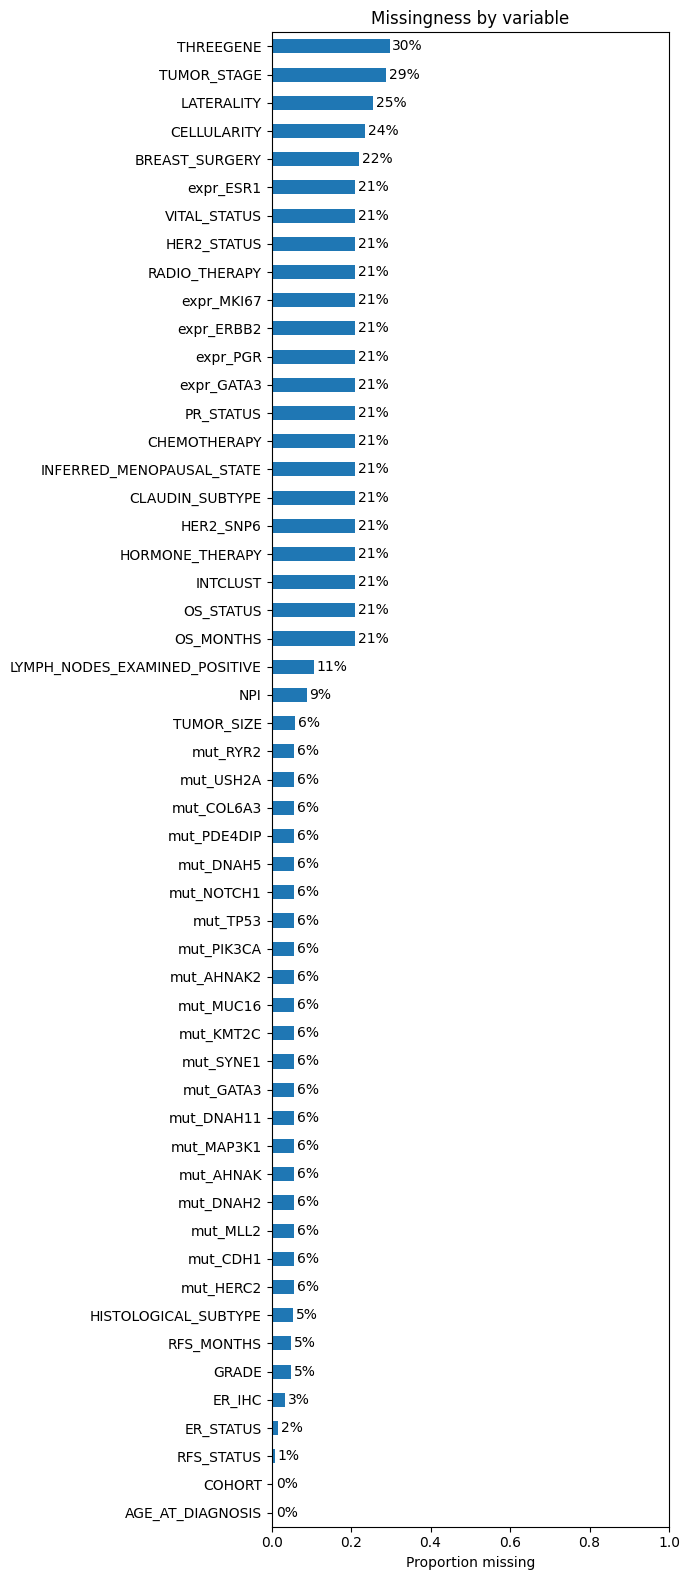

8 columns are complete and not shown


In [10]:
import matplotlib.pyplot as plt

prop_missing = wide.isna().mean().sort_values()          # proportion missing per column, smallest first
n_complete = (prop_missing == 0).sum()
prop_missing = prop_missing[prop_missing > 0]            # only plot columns with some missing

ax = prop_missing.plot.barh(figsize=(7, max(3, 0.3 * len(prop_missing))))
ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in prop_missing], padding=2)
ax.set_xlim(0, 1)
ax.set_xlabel("Proportion missing")
ax.set_title("Missingness by variable")
plt.tight_layout()
plt.show()

print(f"{n_complete} columns are complete and not shown")

The variables with the most missingness were THREEGENE (30%), TUMOR_STAGE (29%), LATERALITY (25%), CELLULARITY (24%), and BREAST_SURGERY (22%). Additionally, all five expression columns and 17 clinical columns have a missingness of 21%. 21 variables, including tumor size and 20 mutation variables, have 6% missingness. For the mutation columns, this missingness implies that these patients weren't sequenced.

**Dataset Level Missingness - Nullity Matrix**

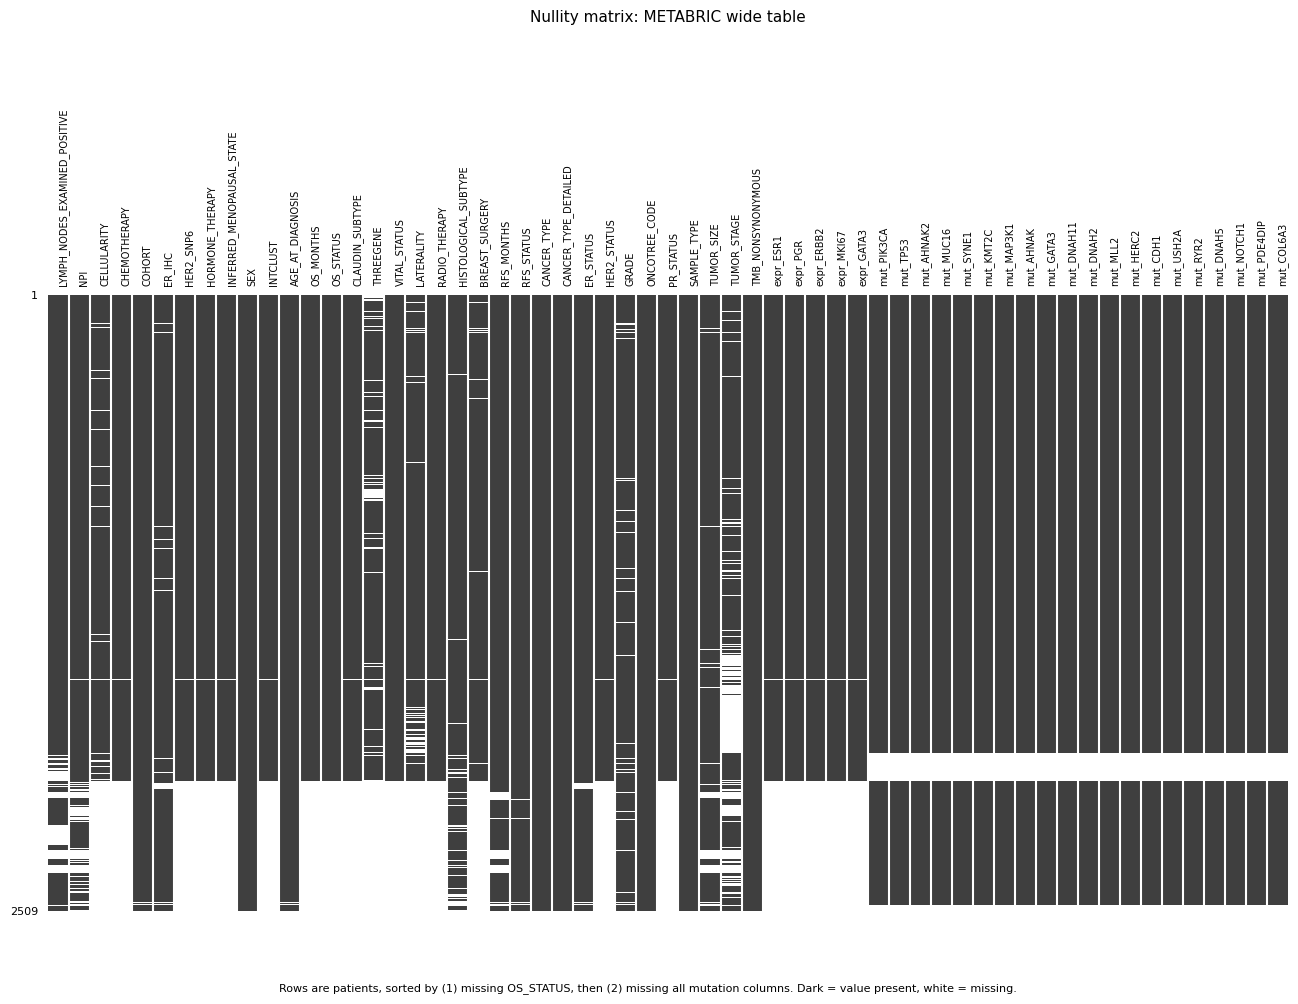

1866 of 2509


In [11]:
import missingno as msno
import matplotlib.pyplot as plt

# Define the column order for visualization
col_order = clin_cols + expr_cols + mut_cols

# Sort rows so patients with the same missing pattern sit together
df = wide.assign(
    _no_outcome = wide["OS_STATUS"].isna(),
    _no_mut     = wide[mut_cols].isna().all(axis=1),
).sort_values(["_no_outcome", "_no_mut"])[col_order]

# nullity matrix with column labels
ax = msno.matrix(df, figsize=(16, 8), fontsize=7, sparkline=False,
                 labels=True, label_rotation=90)
ax.set_title("Nullity matrix: METABRIC wide table", pad=62, fontsize=11)
plt.figtext(0.5, 0.01,
            "Rows are patients, sorted by (1) missing OS_STATUS, then (2) missing all mutation columns. "
            "Dark = value present, white = missing.",
            ha="center", fontsize=8)
plt.savefig("nullity_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# how many patients have the outcome, all expression columns and all mutation columns?
core = ["OS_MONTHS", "OS_STATUS"] + expr_cols + mut_cols
print(wide[core].notna().all(axis=1).sum(), "of", len(wide))

This nullity matrix aligns with the patterns of missing data from the ordered bar chart of proportion missing. The clinical columns that had 21% missing have the same rows/patients missing. Additionally, the mutation variables have the same rows/patients missing.

**Dataset Level Missingness - Correlation Heatmap for the Clinical Data**

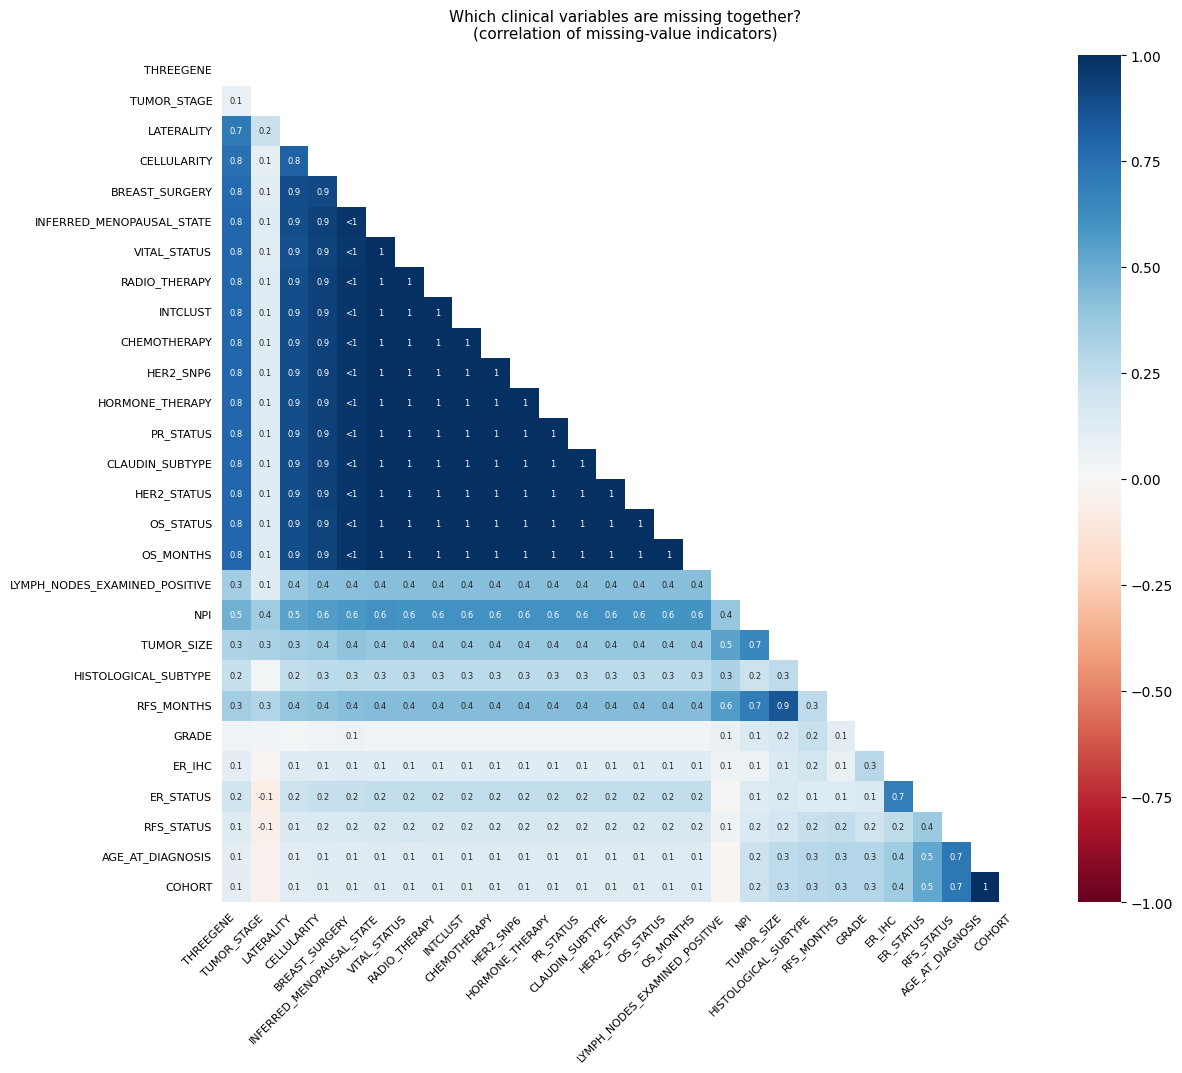

In [12]:
import missingno as msno
import matplotlib.pyplot as plt

# Keep clinical columns with some missing values; sort emptiest first so blocks sit together
missing_cols = [c for c in clin_cols if wide[c].isna().any()]
order = wide[missing_cols].isna().mean().sort_values(ascending=False).index

ax = msno.heatmap(wide[order], figsize=(13, 11), fontsize=8, labels=True)
ax.set_title("Which clinical variables are missing together?\n(correlation of missing-value indicators)",
             fontsize=11, pad=12)
plt.savefig("nullity_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

I've created a correlation heatmap for the clinical variables. The 12 variables: VITAL_STATUS, RADIO_THERAPY, INTCLUST, CHEMOTHERAPY, HER2_SNP6, HORMONE_THERAPY, PR_STATUS, CLAUDIN_SUBTYPE, HER2_STATUS, OS_STATUS, and OS_MONTHS are missing for the same patients. BREAST_SURGERY, CELLULARITY, LATERALITY, and THREEGENE mostly follow this block, while TUMOR_STAGE and GRADE are missing largely independently of it.

**Dataset Level Missingness - UpSet Plot**

1098 of 2509 patients have none of these variables missing


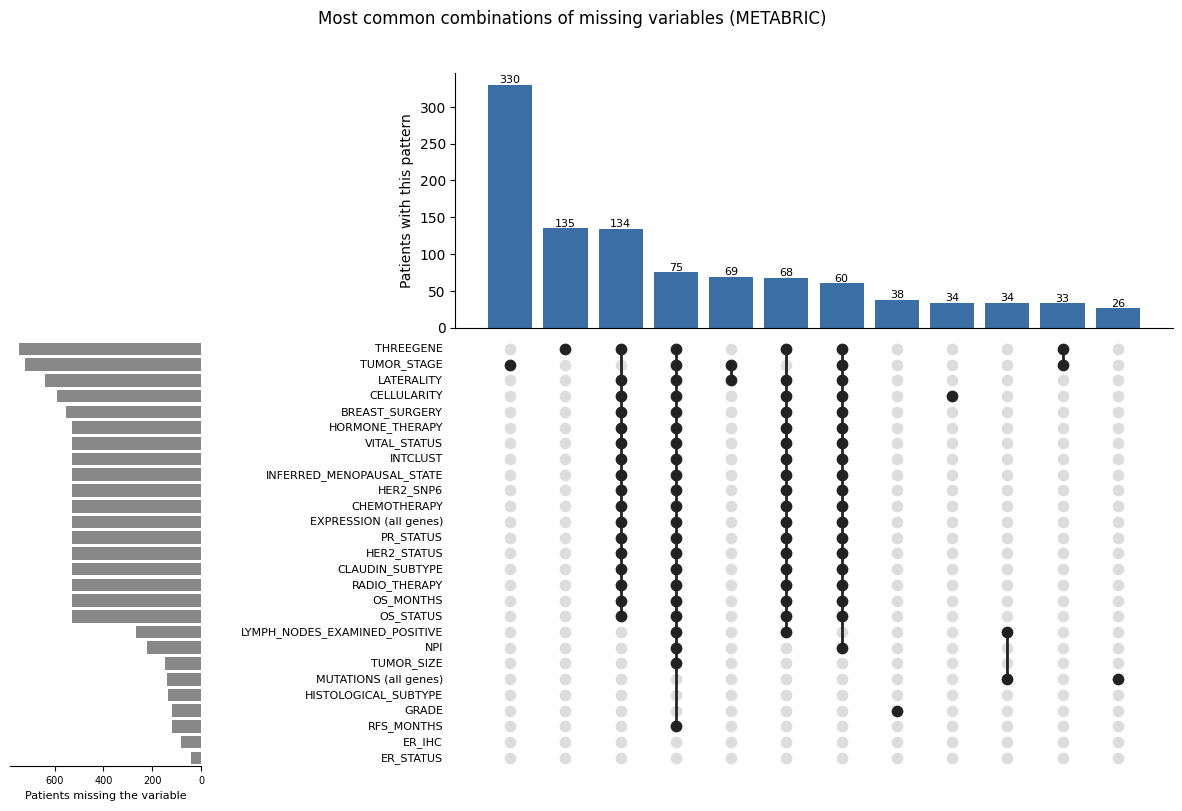

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# one yes/no column per variable: is it missing?
miss = wide[clin_cols].isna()
miss = miss.loc[:, miss.mean() >= 0.01]                                  # skip variables missing for <1% of patients
miss["EXPRESSION (all genes)"] = wide[expr_cols].isna().all(axis=1)      # whole assay missing
miss["MUTATIONS (all genes)"]  = wide[mut_cols].isna().all(axis=1)

# count patients per distinct missing pattern
patterns = miss.value_counts()
n_complete = patterns.get(tuple([False] * miss.shape[1]), 0)
patterns = patterns[[any(p) for p in patterns.index]].head(12)           # 12 most common patterns with something missing
print(f"{n_complete} of {len(miss)} patients have none of these variables missing")

# variables ordered by how often they are missing
order = miss.sum().sort_values(ascending=False).index.tolist()
col_pos = {name: i for i, name in enumerate(miss.columns)}

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, width_ratios=[1.6, 2.0, 6], height_ratios=[3, 5], hspace=0.04, wspace=0.02)
ax_bar = fig.add_subplot(gs[0, 2])
ax_mat = fig.add_subplot(gs[1, 2], sharex=ax_bar)
ax_tot = fig.add_subplot(gs[1, 0], sharey=ax_mat)
ax_lab = fig.add_subplot(gs[1, 1], sharey=ax_mat)

x = np.arange(len(patterns))
y = np.arange(len(order))

# top: patients per pattern
ax_bar.bar(x, patterns.values, color="#3b6ea5")
for xi, v in zip(x, patterns.values):
    ax_bar.text(xi, v, f"{v}", ha="center", va="bottom", fontsize=8)
ax_bar.set_ylabel("Patients with this pattern")
ax_bar.tick_params(labelbottom=False)
ax_bar.spines[["top", "right"]].set_visible(False)

# middle: dot matrix
for xi, pattern in zip(x, patterns.index):
    ax_mat.scatter([xi] * len(order), y, s=55, color="#dddddd", zorder=1)
    on = [yi for yi, name in enumerate(order) if pattern[col_pos[name]]]
    ax_mat.scatter([xi] * len(on), on, s=55, color="#222222", zorder=3)
    if len(on) > 1:
        ax_mat.plot([xi, xi], [min(on), max(on)], color="#222222", lw=2, zorder=2)
ax_mat.set_ylim(len(order) - 0.5, -0.5)
ax_mat.set_xticks([]); ax_mat.set_yticks([])
for s in ["top", "right", "bottom", "left"]:
    ax_mat.spines[s].set_visible(False)

# variable names
ax_lab.axis("off")
for yi, name in enumerate(order):
    ax_lab.text(0.98, yi, name, ha="right", va="center", fontsize=8,
                transform=ax_lab.get_yaxis_transform())

# left: counts
ax_tot.barh(y, miss[order].sum().values, color="#888888")
ax_tot.invert_xaxis()
ax_tot.set_xlabel("Patients missing the variable", fontsize=8)
ax_tot.tick_params(left=False, labelleft=False, labelsize=7)
ax_tot.spines[["top", "left", "right"]].set_visible(False)

fig.suptitle("Most common combinations of missing variables (METABRIC)", y=0.95)
plt.savefig("upset_missingness.png", dpi=200, bbox_inches="tight")
plt.show()

The UpSet plot of the METABRIC dataset reveals that while a robust core subset of 1,098 patients (~44%) has completely observed clinical, mutational, and gene expression profiles, the remaining cohort exhibits distinct patterns of missing data. Isolated clinical missingness occurs in modest, independent fractions—such as 330 patients missing only tumor stage, 135 missing only three-gene classifications, and 38 missing only tumor grade—suggesting administrative omissions or localized test failures (which is *consistent with* a Missing at Random mechanism). In contrast, a highly systematic, coordinated pattern of missingness affects a large chunk of the cohort: approximately 337 patients are missing a massive, identical block of 17 clinical indicators alongside their entire microarray gene expression profiles, highlighting a major assay or processing run omission. On the other hand, missingness in the mutational panel is largely decoupled from these expression gaps, occurring as isolated omissions for only 60 patients (2.4%), which points to distinct operational pipelines for sequencing and microarray profiling within the study.

**Mechanism Level Missingness - Margin Scatter**

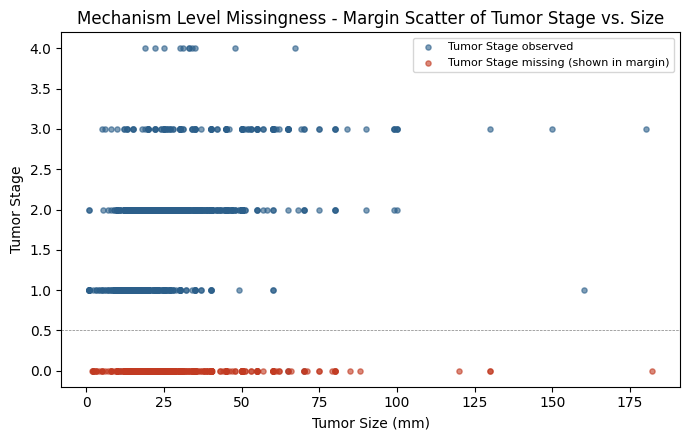

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Filter for cases where we have Tumor Size (X-axis) to locate them horizontally
aq = wide[wide["TUMOR_SIZE"].notna()].copy()

# Identify observed and missing Tumor Stage cases
obs = aq[aq["TUMOR_STAGE"].notna()]
mis = aq[aq["TUMOR_STAGE"].isna()]

# Position missing Tumor Stage values in the margin below the lowest observed stage (e.g., Stage 1)
margin_y = 0.0

fig, ax = plt.subplots(figsize=(7, 4.5))

# Scatter observed stages
ax.scatter(obs["TUMOR_SIZE"], obs["TUMOR_STAGE"], s=14, color="#2c5f8a", alpha=0.6, label="Tumor Stage observed")

# Scatter missing stages in the bottom margin
ax.scatter(mis["TUMOR_SIZE"], np.full(len(mis), margin_y), s=14, color="#c23b22", alpha=0.6,
           label="Tumor Stage missing (shown in margin)")

# Divider line to separate margin data from the actual scale
ax.axhline(margin_y + 0.5, lw=0.5, color="gray", linestyle="--")

ax.set_xlabel("Tumor Size (mm)")
ax.set_ylabel("Tumor Stage")
ax.set_title("Mechanism Level Missingness - Margin Scatter of Tumor Stage vs. Size")
ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

### **Interpretation and Scientific Justification for Margin Scatter & Conditional ECDFs**

#### **1. Why We Chose `TUMOR_SIZE` and `TUMOR_STAGE`**
In clinical oncology datasets, choosing the relationship between **Tumor Size (continuous, in mm)** and **Tumor Stage (ordinal categorical)** is highly strategic for diagnostic missingness analysis due to their direct clinical and biological coupling:
* **Direct Clinical Co-dependence:** Tumor Stage (typically AJCC staging) is determined in large part by the physical size of the primary tumor ($T$ stage in the TNM staging system). Therefore, they are intrinsically correlated; larger tumor sizes should deterministically associate with higher tumor stages.
* **Diagnostic Proxy:** Since tumor size is a direct measurement from surgical pathology or imaging, while stage is a synthetic clinical assessment requiring synthesis of size, lymph nodes, and metastases, we can test if clinicians were less likely to formally record stage depending on the physical severity (size) of the disease.

---

#### **2. Interpretation of the Margin Scatter Plot**
* **The Visual Objective:** A standard scatter plot of `TUMOR_SIZE` vs `TUMOR_STAGE` completely ignores patients with missing stage values, introducing a severe selection bias. The **Margin Scatter** resolves this by placing the patients missing `TUMOR_STAGE` into a designated bottom margin ($y = 0.0$), aligned by their true physical `TUMOR_SIZE` (shown in red).
* **Our Empirical Findings:** Looking at our actual generated margin scatter plot, the red dots in the bottom margin (patients missing `TUMOR_STAGE`) are scattered broadly across the entire horizontal range of `TUMOR_SIZE` (from <10mm to well over 100mm). This visual pattern suggests that stage is missing across various physical severities, signaling an MCAR-like or broadly spread distribution rather than a severe, single-sided boundary truncation.

**Mechanism Level Missingness - Conditional ECDFs**

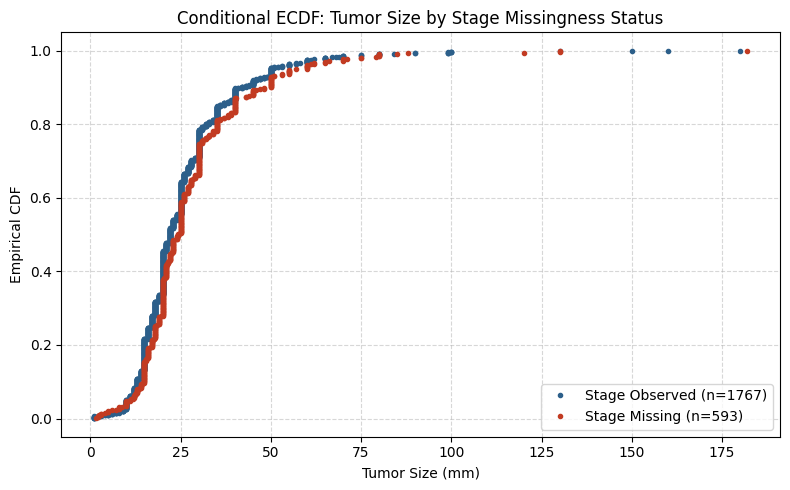

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# We will plot the ECDF of Tumor Size, grouped by whether Tumor Stage is missing
tumor_size_valid = wide[wide["TUMOR_SIZE"].notna()]

# Group 1: Tumor Stage is observed
obs_group = tumor_size_valid[tumor_size_valid["TUMOR_STAGE"].notna()]["TUMOR_SIZE"]
# Group 2: Tumor Stage is missing
mis_group = tumor_size_valid[tumor_size_valid["TUMOR_STAGE"].isna()]["TUMOR_SIZE"]

def ecdf(data):
    """Compute ECDF for a 1D array."""
    x = np.sort(data)
    y = np.arange(1, len(data) + 1) / len(data)
    return x, y

fig, ax = plt.subplots(figsize=(8, 5))

# Calculate and plot ECDF for observed group
x_obs, y_obs = ecdf(obs_group)
ax.plot(x_obs, y_obs, marker='.', linestyle='none', color='#2c5f8a', label=f'Stage Observed (n={len(obs_group)})')

# Calculate and plot ECDF for missing group
x_mis, y_mis = ecdf(mis_group)
ax.plot(x_mis, y_mis, marker='.', linestyle='none', color='#c23b22', label=f'Stage Missing (n={len(mis_group)})')

ax.set_xlabel('Tumor Size (mm)')
ax.set_ylabel('Empirical CDF')
ax.set_title('Conditional ECDF: Tumor Size by Stage Missingness Status')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

#### **3. Interpretation of the Conditional ECDF (Empirical Cumulative Distribution Function)**
* **The Visual Objective:** The ECDF maps out the exact cumulative distribution of `TUMOR_SIZE` for two distinct sub-populations: those with an observed tumor stage (blue) and those with a missing tumor stage (red).
* **Our Empirical Findings:** Our actual plotted ECDF curves for the "Stage Observed" ($n=1767$) and "Stage Missing" ($n=593$) groups show an almost perfect, overlapping trajectory across the entire distribution of tumor sizes. There is no significant horizontal separation or divergence between the blue and red curves. This highly identical behavior provides robust quantitative justification that the missingness of `TUMOR_STAGE` is independent of `TUMOR_SIZE`, strongly validating a **Missing Completely at Random (MCAR)** mechanism relative to tumor size.

# **Investigating the Data Structure Using PCA and k-means**

**Principal Components Analysis**

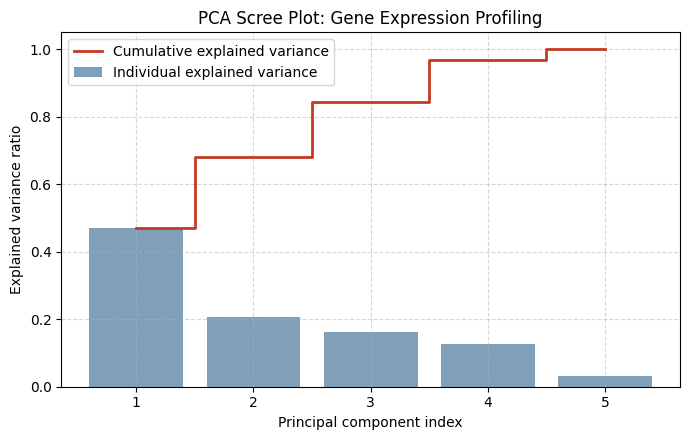

Explained variance by PC1: 47.15%
Explained variance by PC2: 20.80%
Total explained variance by PC1 & PC2: 67.95%


In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

# Extract gene expression columns for PCA
expr_features = genetic_only[clean_expr_cols].dropna()
patients_with_expr = expr_features.index

# Standardize features before applying PCA
scaler = StandardScaler()
expr_scaled = scaler.fit_transform(expr_features)

# Fit PCA
pca = PCA(n_components=5)
pca_transformed = pca.fit_transform(expr_scaled)

# Calculate explained variance ratios
var_ratio = pca.explained_variance_ratio_
cum_var_ratio = np.cumsum(var_ratio)

# Create variance explained plot
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(1, 6), var_ratio, alpha=0.6, align='center', label='Individual explained variance', color='#2c5f8a')
ax.step(range(1, 6), cum_var_ratio, where='mid', label='Cumulative explained variance', color='#c23b22', lw=2)

ax.set_ylabel('Explained variance ratio')
ax.set_xlabel('Principal component index')
ax.set_title('PCA Scree Plot: Gene Expression Profiling')
ax.set_xticks(range(1, 6))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='best')

plt.tight_layout()
plt.show()

print(f'Explained variance by PC1: {var_ratio[0]:.2%}')
print(f'Explained variance by PC2: {var_ratio[1]:.2%}')
print(f'Total explained variance by PC1 & PC2: {cum_var_ratio[1]:.2%}')

PC1 alone captures 47.15% of the total variance in the expression of the selected genes (ESR1, PGR, ERBB2, MKI67, GATA3). PC2 captures 20.80% of the variance.
Together, the first two principal components explain 67.95% of the total variation. This high cumulative percentage justifies using a 2D projection (PC1 vs. PC2) to represent and analyze the structure of this multi-gene expression space.

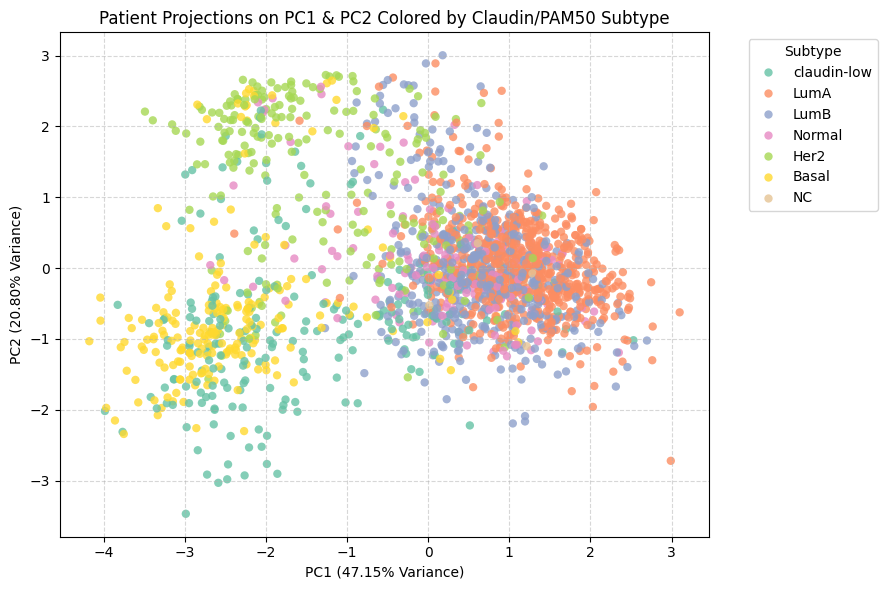

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Create a DataFrame containing our principal components and merge with PAM50 subtypes
pca_df = pd.DataFrame(
    pca_transformed[:, :2],
    columns=['PC1', 'PC2'],
    index=patients_with_expr
).join(wide[['CLAUDIN_SUBTYPE']], how='left')

# Handle any missing subtype labels for visualization
pca_df['CLAUDIN_SUBTYPE'] = pca_df['CLAUDIN_SUBTYPE'].fillna('Unknown')

# Plot patients in PC space colored by subtype
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='CLAUDIN_SUBTYPE',
    palette='Set2',
    alpha=0.8,
    edgecolor='none'
)

plt.title('Patient Projections on PC1 & PC2 Colored by Claudin/PAM50 Subtype')
plt.xlabel(f'PC1 ({var_ratio[0]:.2%} Variance)')
plt.ylabel(f'PC2 ({var_ratio[1]:.2%} Variance)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Subtype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

When projecting patients onto PC1 and PC2, different molecular subtypes of breast cancer segregate.
Luminal (LumA and LumB) tumors cluster tightly along the right side of the PC1 axis (characterized by high expression of hormone receptor-related genes like ESR1, PGR, and GATA3).
Basal-like and claudin-low tumors map to the far left of PC1, indicating a lack of these luminal markers.
HER2-enriched tumors separate along PC2, driven heavily by high ERBB2 expression.

**k-means Clustering using k=4**

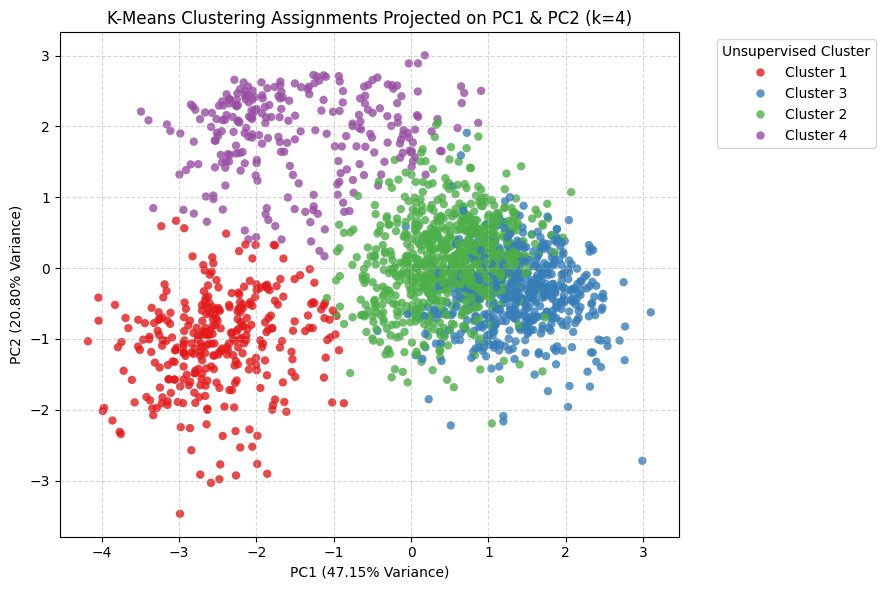

KMeans_Cluster,Cluster 1,Cluster 2,Cluster 3,Cluster 4
CLAUDIN_SUBTYPE,,,,
Basal,168,11,6,24
Her2,21,51,12,140
LumA,1,336,345,18
LumB,1,299,141,34
NC,0,4,2,0
Normal,9,79,43,17
claudin-low,128,55,11,24


In [18]:
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

# Run K-Means Clustering on the standardized expression data
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(expr_scaled)

# Add the cluster assignments to our PCA DataFrame
pca_df['KMeans_Cluster'] = [f'Cluster {label + 1}' for label in kmeans_labels]

# Plot the patients in the PC space colored by unsupervised KMeans clusters
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='KMeans_Cluster',
    palette='Set1',
    alpha=0.8,
    edgecolor='none'
)

plt.title('K-Means Clustering Assignments Projected on PC1 & PC2 (k=4)')
plt.xlabel(f'PC1 ({var_ratio[0]:.2%} Variance)')
plt.ylabel(f'PC2 ({var_ratio[1]:.2%} Variance)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Unsupervised Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Print cross-tabulation table to compare unsupervised clusters with annotated PAM50 subtypes
pd.crosstab(pca_df['CLAUDIN_SUBTYPE'], pca_df['KMeans_Cluster'])

The unsupervised clustering (K-Means) is highly congruent with supervised biological classifications (Claudin/PAM50), proving that key clinical phenotypes of breast cancer are fundamentally driven by the distinct expression profiles of these 5 core genes.

# **Regularized Model: Multinomial Lasso / Elastic Net for PAM50 Subtype**

**Aim (proposal, Methods table).** Predict PAM50 subtype from gene expression with a multinomial lasso or elastic net (scikit-learn logistic regression), where the penalty picks a small gene set and is tuned in inner folds.

**Run first:** the cells above through the **Join** step, which create `clinical` and the full gene-by-sample matrix `expr`.

**How the design keeps test patients out of every decision**

| Step | Where it is fit |
|---|---|
| Drop genes with too many missing values | Training folds only |
| Median imputation | Training folds only |
| Keep the top genes by ANOVA F (fast pre-filter so the solver is feasible on about 20,000 genes) | Training folds only |
| Standardize each gene | Training folds only |
| Choose penalty strength `C` and lasso/elastic-net mix `l1_ratio` | Inner folds only |
| Report performance | Outer test folds, never used above |

Inner folds refit all preprocessing too, because the steps live inside one scikit-learn `Pipeline`.

**How "a small gene set" is enforced.** Penalty selection uses inner-fold results only, in two steps. First, only penalties that keep at most `MAX_PANEL_GENES` genes on average are eligible; the default of 50 matches the PAM50 panel size so the comparison with the nearest-centroid baseline is like for like. Second, among eligible penalties, take the one with the fewest genes whose log loss is within one standard error of the best eligible log loss. An unconstrained best-log-loss model is also scored, so the table below shows what the small panel costs.

**Choices to confirm with Tirzah** (they must match the random forest and baselines): the label classes in `KEEP_CLASSES`, the `MAX_GENE_MISSING` cut-off, `N_FILTER_GENES` and `MAX_PANEL_GENES`.

In [ ]:
import time
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ---------- Analysis decisions: change these, nothing below needs editing ----------
KEEP_CLASSES     = ["LumA", "LumB", "Her2", "Basal", "Normal"]  # five PAM50 classes; claudin-low and NC are excluded
MAX_GENE_MISSING = 0.20   # drop a gene if more than this share of training patients lack it; set from the table below
N_FILTER_GENES   = 2000   # genes passed to the penalty after the training-fold ANOVA filter
MAX_PANEL_GENES  = 50     # largest gene set the tuning may choose (average across inner folds)
OUTER_FOLDS      = 5      # performance estimate
INNER_FOLDS      = 5      # tuning; use 3 for a faster draft run
C_GRID           = np.geomspace(0.004, 0.15, 9) # inverse penalty strength: smaller C keeps fewer genes
L1_RATIOS        = [1.0, 0.5]                   # 1.0 = lasso, 0.5 = elastic net
MAX_ITER         = 3000
SEED             = 707

# ---------- Align expression with labels (one sample per patient) ----------
assert clinical["PATIENT_ID"].is_unique and clinical["SAMPLE_ID"].is_unique

labels = clinical.set_index("SAMPLE_ID")["CLAUDIN_SUBTYPE"]
X_all  = expr.T                                               # rows = samples, columns = genes
both   = X_all.index.intersection(labels.dropna().index)      # patients with expression and a subtype label
subtype = labels.loc[both]

print(f"{len(both)} of {len(clinical)} patients have expression and a subtype label")
print("\nClass counts before exclusions:")
print(subtype.value_counts().to_string())

keep = subtype.isin(KEEP_CLASSES).to_numpy()
X = X_all.loc[both[keep]]
y = subtype[keep].to_numpy()
classes = np.array(sorted(KEEP_CLASSES))
gene_names = X.columns.to_numpy()

print(f"\nModelling set: {X.shape[0]} patients, {X.shape[1]} genes, {len(classes)} classes")

# Description only (all patients): how much is missing per gene, for choosing MAX_GENE_MISSING.
# The actual dropping happens inside each training fold.
gene_missing = X.isna().mean()
print("\nGenes by share of patients missing:")
for cut in [0, 0.01, 0.05, 0.10, 0.20, 0.50, 0.999]:
    print(f"  more than {cut:>6.1%} missing: {(gene_missing > cut).sum():>6} genes")

In [ ]:
class MissingnessFilter(TransformerMixin, BaseEstimator):
    # Drops genes missing in more than max_missing of the patients it is fit on.
    def __init__(self, max_missing=0.2):
        self.max_missing = max_missing

    def fit(self, X, y=None):
        self.keep_ = np.isnan(np.asarray(X, dtype=float)).mean(axis=0) <= self.max_missing
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)[self.keep_]


def make_model():
    # scikit-learn 1.8 deprecated `penalty`. On older versions l1_ratio is ignored unless
    # penalty="elasticnet" is set, which would silently fit a ridge model with no gene selection.
    major_minor = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
    extra = {"penalty": "elasticnet"} if major_minor < (1, 8) else {}
    clf = LogisticRegression(solver="saga", tol=1e-3, max_iter=MAX_ITER, random_state=SEED, **extra)
    return Pipeline([
        ("drop_missing", MissingnessFilter(MAX_GENE_MISSING)),
        ("impute",       SimpleImputer(strategy="median")),
        ("filter",       SelectKBest(f_classif, k=N_FILTER_GENES)),
        ("scale",        StandardScaler()),
        ("clf",          clf),
    ])


def count_genes(model, X=None, y=None):
    # A gene counts as selected if its coefficient is nonzero for at least one subtype.
    return int(np.any(model.named_steps["clf"].coef_ != 0, axis=0).sum())


def hit_iter_limit(model, X=None, y=None):
    return float(np.max(model.named_steps["clf"].n_iter_) >= MAX_ITER)


def choose_penalty(cv):
    # Uses inner-fold results only: restrict to small panels, then apply the one-standard-error rule.
    mean    = cv["mean_test_log_loss"]                 # negative log loss, so higher is better
    n_genes = cv["mean_test_n_genes"]
    splits  = np.column_stack([cv[f"split{i}_test_log_loss"] for i in range(INNER_FOLDS)])
    eligible = np.where(n_genes <= MAX_PANEL_GENES)[0]
    if eligible.size == 0:                             # every penalty kept too many genes: take the sparsest
        return int(np.argmin(n_genes))
    best   = eligible[np.argmax(mean[eligible])]
    se     = splits[best].std(ddof=1) / np.sqrt(INNER_FOLDS)
    within = eligible[mean[eligible] >= mean[best] - se]
    order  = np.lexsort((-mean[within], n_genes[within]))   # fewest genes, then best loss
    return int(within[order[0]])


def tune(X_train, y_train):
    # Everything inside this search, preprocessing included, is refit on each inner training split.
    search = GridSearchCV(
        make_model(),
        param_grid={"clf__C": list(C_GRID), "clf__l1_ratio": list(L1_RATIOS)},
        scoring={"log_loss": "neg_log_loss", "n_genes": count_genes, "unconverged": hit_iter_limit},
        refit=choose_penalty,
        cv=StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=SEED + 1),
        n_jobs=-1,
        error_score="raise",
    )
    return search.fit(X_train, y_train)


def selected_genes(model):
    # Coefficient table (standardized scale) for genes with any nonzero coefficient.
    kept = model[:-1].get_feature_names_out(gene_names)
    coef = pd.DataFrame(model.named_steps["clf"].coef_.T, index=kept, columns=classes)
    return coef.loc[(coef != 0).any(axis=1)]


def score(y_true, proba):
    return {
        "log_loss":          log_loss(y_true, proba, labels=classes),
        "macro_auroc":       roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=classes),
        "balanced_accuracy": balanced_accuracy_score(y_true, classes[proba.argmax(axis=1)]),
    }

In [ ]:
# Nested cross-validation: outer folds estimate performance, inner folds (inside tune) pick the penalty.
X_values = X.to_numpy(dtype=float)
outer = StratifiedKFold(OUTER_FOLDS, shuffle=True, random_state=SEED)

oof_proba = np.full((len(y), len(classes)), np.nan)    # small-panel model's out-of-fold probabilities
oof_fold  = np.zeros(len(y), dtype=int)
fold_rows, fold_genes, grid_flags = [], [], []

start = time.time()
for fold, (train, test) in enumerate(outer.split(X_values, y), start=1):
    assert not set(train) & set(test)
    search = tune(X_values[train], y[train])

    # Model used for reporting: small panel chosen by choose_penalty
    sparse_model = search.best_estimator_
    proba = sparse_model.predict_proba(X_values[test])
    oof_proba[test], oof_fold[test] = proba, fold

    # Comparison only: the penalty with the best inner log loss, with no limit on panel size
    best_i = int(np.argmax(search.cv_results_["mean_test_log_loss"]))
    best_params = search.cv_results_["params"][best_i]
    best_model = clone(make_model()).set_params(**best_params).fit(X_values[train], y[train])
    best_proba = best_model.predict_proba(X_values[test])

    genes = selected_genes(sparse_model)
    fold_genes.append(set(genes.index))
    fold_rows.append({
        "fold": fold,
        "C": search.best_params_["clf__C"],
        "l1_ratio": search.best_params_["clf__l1_ratio"],
        "n_genes": len(genes),
        **score(y[test], proba),
        "best_loss_C": best_params["clf__C"],
        "best_loss_l1_ratio": best_params["clf__l1_ratio"],
        "best_loss_n_genes": len(selected_genes(best_model)),
        **{f"best_loss_{k}": v for k, v in score(y[test], best_proba).items()},
        "share_inner_fits_unconverged": search.cv_results_["mean_test_unconverged"].mean(),
    })
    for name, c in [("small-panel model", search.best_params_["clf__C"]), ("comparison best-loss model", best_params["clf__C"])]:
        if c in (C_GRID[0], C_GRID[-1]):
            grid_flags.append(f"fold {fold}: {name} C={c:.4f} is at the edge of C_GRID")
    print(f"Fold {fold}/{OUTER_FOLDS} done at {(time.time() - start) / 60:.1f} min, {len(genes)} genes")

assert not np.isnan(oof_proba).any()
results = pd.DataFrame(fold_rows).set_index("fold")
print("\nGrid-edge notes (widen C_GRID if the small-panel model appears):", grid_flags or "none")
print(f"Largest share of inner fits that hit MAX_ITER: {results['share_inner_fits_unconverged'].max():.1%}")
results

In [ ]:
# Outer-fold performance: mean and SD across folds, for the small-panel and unconstrained models
metrics = ["n_genes", "log_loss", "macro_auroc", "balanced_accuracy"]
summary = pd.DataFrame({
    "Small-panel model (reported): mean": results[metrics].mean(),
    "Small-panel model: SD": results[metrics].std(),
    "Unconstrained best-loss model: mean": results[[f"best_loss_{m}" for m in metrics]].mean().to_numpy(),
    "Unconstrained best-loss model: SD": results[[f"best_loss_{m}" for m in metrics]].std().to_numpy(),
}).round(3)
display(summary)

# Pooled out-of-fold results for the reported model
per_class_auroc = pd.Series(
    {c: roc_auc_score(y == c, oof_proba[:, i]) for i, c in enumerate(classes)}, name="one_vs_rest_auroc"
).round(3)
display(per_class_auroc.to_frame())

pred = classes[oof_proba.argmax(axis=1)]
display(pd.DataFrame(confusion_matrix(y, pred, labels=classes),
                     index=[f"true {c}" for c in classes], columns=[f"pred {c}" for c in classes]))

# Saved so calibration and by-cohort / by-ER evaluation can reuse honest out-of-fold predictions
oof = pd.DataFrame(oof_proba, index=X.index, columns=[f"p_{c}" for c in classes])
oof.insert(0, "outer_fold", oof_fold)
oof.insert(0, "y_true", y)
oof.to_csv("lasso_oof_predictions.csv")
print("Saved lasso_oof_predictions.csv:", oof.shape)

In [ ]:
# Final gene panel: repeat the whole tuning procedure on all modelling patients.
# The performance estimate for this procedure is the nested-CV result above, not a refit score on these patients.
final_search = tune(X_values, y)
final_model  = final_search.best_estimator_
panel = selected_genes(final_model)

# PAM50 list from Parker et al. 2009; older and newer symbols are both included so overlap is not undercounted
PAM50 = set('''ACTR3B ANLN BAG1 BCL2 BIRC5 BLVRA CCNB1 CCNE1 CDC20 CDC6 CDCA1 NUF2 CDH3 CENPF CEP55 CXXC5 EGFR
ERBB2 ESR1 EXO1 FGFR4 FOXA1 FOXC1 GPR160 GRB7 KIF2C KNTC2 NDC80 KRT14 KRT17 KRT5 MAPT MDM2 MELK MIA MKI67 MLPH
MMP11 MYBL2 MYC NAT1 ORC6 ORC6L PGR PHGDH PTTG1 RRM2 SFRP1 SLC39A6 TMEM45B TYMS UBE2C UBE2T'''.split())

# How often each gene was chosen across the outer folds (stability of the selection)
freq = pd.Series({g: sum(g in s for s in fold_genes) for g in set.union(*fold_genes) | set(panel.index)})
panel_out = panel.copy()
panel_out.insert(0, "in_PAM50", panel_out.index.isin(PAM50))
panel_out.insert(1, f"outer_folds_selected_of_{OUTER_FOLDS}", freq.reindex(panel_out.index).fillna(0).astype(int))
panel_out = panel_out.sort_values(f"outer_folds_selected_of_{OUTER_FOLDS}", ascending=False)
panel_out.to_csv("lasso_selected_genes.csv")

pairs = [(a, b) for i, a in enumerate(fold_genes) for b in fold_genes[i + 1:]]
jaccard = np.mean([len(a & b) / len(a | b) if a | b else np.nan for a, b in pairs])

cols = ["param_clf__l1_ratio", "param_clf__C", "mean_test_log_loss", "std_test_log_loss", "mean_test_n_genes"]
tuning = pd.DataFrame(final_search.cv_results_)[cols].rename(columns={
    "param_clf__l1_ratio": "l1_ratio", "param_clf__C": "C", "mean_test_log_loss": "inner_neg_log_loss",
    "std_test_log_loss": "sd_across_inner_folds", "mean_test_n_genes": "mean_genes"})
display(tuning.sort_values(["l1_ratio", "C"]).round(4))

print(f"Chosen penalty: C={final_search.best_params_['clf__C']:.4f}, l1_ratio={final_search.best_params_['clf__l1_ratio']}")
print(f"Final panel: {len(panel_out)} genes, {int(panel_out['in_PAM50'].sum())} of them in PAM50")
print(f"Mean pairwise Jaccard overlap of the outer-fold gene sets: {jaccard:.2f}")
print("Saved lasso_selected_genes.csv")
panel_out.head(30).round(3)

**Reading these results**

- The nested-CV table is the performance estimate. It describes the whole procedure, including gene selection, so it is not the performance of one fixed gene list.
- PAM50 labels were themselves computed from expression, so strong discrimination means the model reproduces the PAM50 call. It is not independent evidence about tumor biology. The nearest-centroid baseline gives the ceiling for that reproduction.
- The panel-size cap is applied to the inner-fold average, so a refit on all training patients can land slightly above `MAX_PANEL_GENES`. Check the `n_genes` column.
- Multinomial lasso penalizes each gene-subtype coefficient separately, so the panel is the union of the genes used for each subtype.
- Low Jaccard overlap across folds means correlated genes are substituting for one another, so individual genes should not be over-interpreted. The elastic net (`l1_ratio=0.5`) usually spreads weight across such groups, at the price of more genes.
- Next from the proposal: per-subtype calibration, using `lasso_oof_predictions.csv` as the starting point, and the sensitivity rerun without the 50 PAM50 genes.